# Question 2 — Saddle point and complementary slackness
**EN3330 — Introduction to Engineering Optimization, Assignment 03**

Using the same function as Question 1,

$$L(\mu,x)=x^2+\mu(1-x),\quad \mu\geq0,$$

with candidate $(x^*,\mu^*)=(1,2)$. We verify the saddle inequalities, the optimality argument, and complementary slackness.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (7.1, 3.7),
    'figure.dpi': 140,
    'savefig.dpi': 250,
    'font.size': 10.5,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.linewidth': .55,
    'grid.alpha': .24,
    'lines.linewidth': 1.9,
    'legend.fontsize': 9,
})

def format_ax(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='both', zorder=0)
    ax.set_axisbelow(True)

def L(mu, x):
    return x**2 + mu*(1 - x)


## 2(a) — Verify the saddle inequalities
We must show

$$L(\mu,1)\leq L(2,1)\leq L(2,x), \qquad \mu\geq0,\;x\in\mathbb R.$$

First, $L(2,1)=1^2+2(1-1)=1$.

For **any** $\mu\geq0$, $L(\mu,1)=1+\mu(0)=1$; therefore the left inequality is an equality.

For any real $x$,

$$L(2,x)=x^2+2(1-x)=(x-1)^2+1\geq1.$$

So the right inequality also holds, and equality occurs at $x=1$.

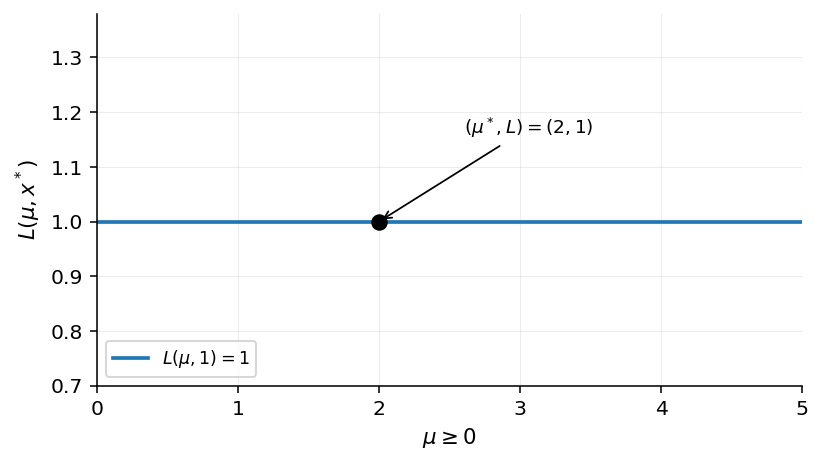

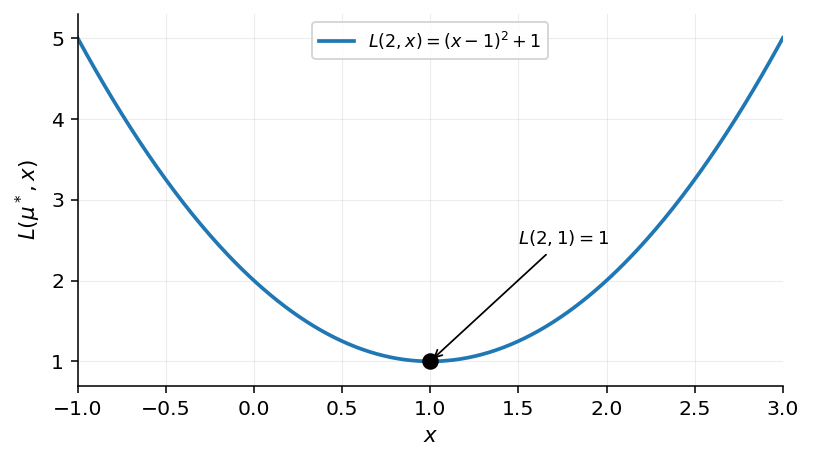

In [2]:
# Figure 4: left saddle inequality
fig,ax=plt.subplots(figsize=(6.5,3.45))
m=np.linspace(0,5,300)
ax.plot(m,np.ones_like(m),label=r'$L(\mu,1)=1$')
ax.scatter([2],[1],s=56,c='black',zorder=5)
ax.annotate(r'$(\mu^*,L)=(2,1)$',xy=(2,1),xytext=(2.6,1.16),arrowprops=dict(arrowstyle='->',lw=.9),fontsize=9.5)
ax.set_xlim(0,5);ax.set_ylim(.7,1.38)
format_ax(ax,r'$\mu\geq0$',r'$L(\mu,x^*)$')
ax.legend(loc='lower left')
fig.savefig(FIG_DIR/'04_saddle_left.png', bbox_inches='tight', pad_inches=.15)
plt.show()

# Figure 5: right saddle inequality
fig,ax=plt.subplots(figsize=(6.5,3.45))
xx=np.linspace(-1,3,400)
ax.plot(xx,(xx-1)**2+1,label=r'$L(2,x)=(x-1)^2+1$')
ax.scatter([1],[1],s=56,c='black',zorder=5)
ax.annotate(r'$L(2,1)=1$',xy=(1,1),xytext=(1.5,2.45),arrowprops=dict(arrowstyle='->',lw=.9),fontsize=9.4)
ax.set_xlim(-1,3);ax.set_ylim(.7,5.3)
format_ax(ax,r'$x$',r'$L(\mu^*,x)$')
ax.legend(loc='upper center')
fig.savefig(FIG_DIR/'05_saddle_right.png', bbox_inches='tight', pad_inches=.15)
plt.show()

**Interpretation.** When $x=1$, changing the multiplier does not change the Lagrangian. When $\mu=2$, moving away from $x=1$ only increases it. This is the saddle-point property.

## 2(b) — Explain the optimality argument
For every feasible $x\geq1$,

$$\underbrace{f(x^*)=L(\mu^*,x^*)}_{(1)}\ \underbrace{\leq}_{(2)}\
\underbrace{L(\mu^*,x)=f(x)+\mu^*h(x)}_{(3)}\ \underbrace{\leq f(x)}_{(4)}.$$

Reasons:

1. **(1)** $h(x^*)=1-1=0$, so the Lagrangian equals the objective at $x^*$.
2. **(2)** The right saddle inequality gives $L(\mu^*,x^*)\leq L(\mu^*,x)$.
3. **(3)** Substitute the Lagrangian definition $L=f+\mu h$.
4. **(4)** Feasibility gives $h(x)\leq0$; with $\mu^*\geq0$, the product is nonpositive.

Therefore $f(x^*)\leq f(x)$ for every feasible $x$ and $x^*$ is optimal.

**What does the left saddle inequality tell us?** If $h(x^*)>0$, then $L(\mu,x^*)=f(x^*)+\mu h(x^*)$ increases without bound as $\mu\rightarrow\infty$, which violates the fixed upper bound $L(\mu^*,x^*)$. Hence $h(x^*)\leq0$. This verifies feasibility. In our specific case $\mu^*=2>0$; using $\mu=0$ in the left inequality additionally forces $h(x^*)\geq0$. Thus $h(x^*)=0$.

In [3]:
x_star, mu_star = 1.0, 2.0
h = lambda x: 1 - x
print("L(2,1) =", L(mu_star, x_star))
print("h(x*) =", h(x_star))
print("mu* h(x*) =", mu_star*h(x_star))

for feasible_x in (1, 1.5, 2, 4):
    lhs = x_star**2
    mid = L(mu_star, feasible_x)
    rhs = feasible_x**2
    print(f"x={feasible_x:g}: {lhs:g} <= {mid:g} <= {rhs:g}")
    assert lhs <= mid + 1e-12 <= rhs + 1e-12

L(2,1) = 1.0
h(x*) = 0.0
mu* h(x*) = 0.0
x=1: 1 <= 1 <= 1
x=1.5: 1 <= 1.25 <= 2.25
x=2: 1 <= 2 <= 4
x=4: 1 <= 10 <= 16


## 2(c) — Complementary slackness, then relax the constraint
For $x\geq1$, $h(x^*)=0$ and $\mu^*=2$. Consequently,

$$\boxed{\mu^*h(x^*)=2(1-1)=0}.$$

Now replace the constraint by $x\geq-1$, or $\bar h(x)=-1-x\leq0$. The unconstrained minimizer of $x^2$ is $x=0$ and satisfies $0\geq-1$. In fact $\bar h(0)=-1<0$, so the constraint is **inactive**.

Complementary slackness $\bar\mu^*\bar h(0)=0$ requires $\bar\mu^*=0$. Thus $\bar x^*=0$ and $\bar p^*=0$.

An independent dual check follows from

$$\bar L(\mu,x)=x^2+\mu(-1-x),\qquad
\bar d(\mu)=-\mu-\frac{\mu^2}{4}.$$

For $\mu\geq0$, this function is largest at $\mu=0$ and $\bar d^*=0$.

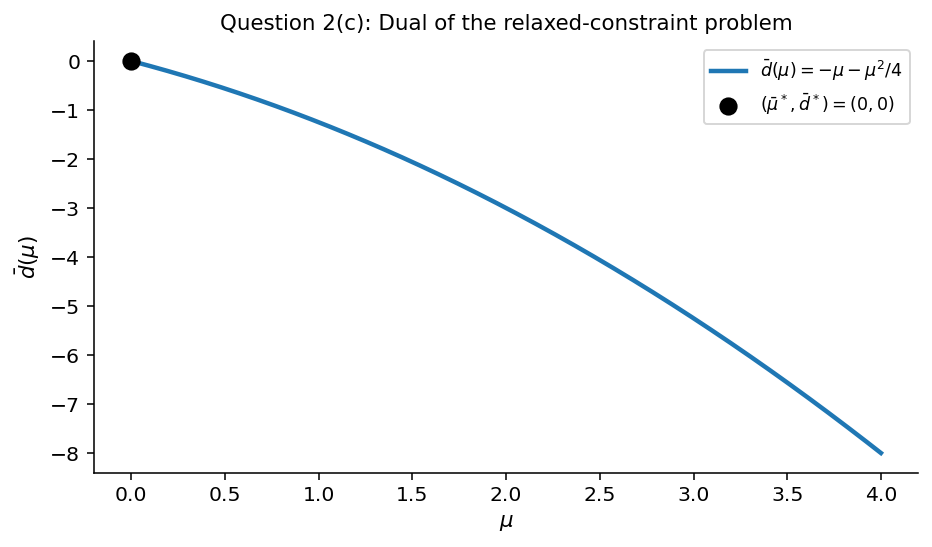

In [4]:
def relaxed_dual(mu):
    return -mu - mu**2/4

mu = np.linspace(0, 4, 500)
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.plot(mu, relaxed_dual(mu), linewidth=2.3, label=r"$\bar d(\mu)=-\mu-\mu^2/4$")
ax.scatter([0], [0], s=70, color="black", zorder=5, label=r"$(\bar\mu^*,\bar d^*)=(0,0)$")
ax.set(xlabel=r"$\mu$", ylabel=r"$\bar d(\mu)$",
       title="Question 2(c): Dual of the relaxed-constraint problem")
ax.legend()
plt.show()
assert np.all(relaxed_dual(mu) <= 1e-12)

**Conclusion.** The original constraint binds at the optimum and has a positive multiplier. After relaxing the constraint to $x\geq-1$, the unconstrained optimum becomes feasible with slack; the multiplier drops to zero.